# 22 Retrieval dan Ranking

Mencari dokumen yang paling relevan untuk sebuah kueri. Contoh: ringkasan IndoSum sebagai kueri, dan artikel
aslinya sebagai jawaban.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Mencari dokumen paling relevan |
| **Unit prediksi** | Satu kueri mendapat daftar dokumen terurut |
| **Metrik** | MRR@10, Recall@k, dan NDCG@10 |
| **Masalah terbesar** | 98,6% artikel lebih panjang dari 128 kata sehingga terpotong untuk embedding, dan kueri di sini sintetis (5 kata acak dari ringkasan), jadi masih memihak pencocokan kata persis. |
| **Data contoh** | IndoSum: 4.449 artikel dan 1.000 kueri buatan |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta mencari dokumen, mencocokkan keluhan dengan kebijakan, atau meranking hasil.
Metriknya biasanya MRR, NDCG, MAP@k, atau Recall@k.

**Yang perlu diganti kalau datanya beda:**
- `corpus`, `queries`, dan `gold`. Kalau jawaban lebih dari satu, sesuaikan fungsi metrik.
- `RERANK_TOP`, makin besar makin akurat tapi makin lambat.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya BM25, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
KS = [1, 5, 10]
RRF_K = 60

SETTINGS = {
    "cepat": {"n_queries": 300, "rerank_top": 20, "query_word_limit": 5},
    "penuh": {"n_queries": 1000, "rerank_top": 50, "query_word_limit": 5},
}[MODE]

seed_everything(SEED)
install_offline("rank-bm25")
print(SETTINGS)

{'n_queries': 1000, 'rerank_top': 50, 'query_word_limit': 5}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Embedding teks.** Kalau pretrained boleh dipakai, teks diubah dengan multilingual-e5. Kalau
tidak boleh, `USE_PRETRAINED=False` memakai TF-IDF + SVD sebagai gantinya.

In [6]:
from sklearn.decomposition import TruncatedSVD  # noqa: E402
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf  # noqa: E402
from sklearn.preprocessing import normalize as _l2  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402


def tfidf_svd_embed(texts: list[str], dim: int = 256) -> np.ndarray:
    """Embedding tanpa pretrained: TF-IDF kata + SVD."""
    matrix = _Tfidf(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    dim = min(dim, matrix.shape[1] - 1, matrix.shape[0] - 1)
    return _l2(TruncatedSVD(dim, random_state=SEED).fit_transform(matrix))


@torch.inference_mode()
def e5_embed(texts: list[str], prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    """Mean pooling multilingual-e5, hasil dinormalisasi L2."""
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "e5")
    model = AutoModel.from_pretrained(MODEL_DIR / "e5").to(DEVICE).eval().half()
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + texts[i] for i in order[start : start + batch_size]]
        tokens = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(DEVICE)
        hidden = model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        chunks.append(torch.nn.functional.normalize(pooled, dim=1).float().cpu().numpy())
    del model
    torch.cuda.empty_cache()
    vectors = np.empty((len(texts), chunks[0].shape[1]), dtype=np.float32)
    vectors[order] = np.vstack(chunks)
    return vectors


def embed_texts(texts: list[str]) -> np.ndarray:
    """Pilih embedding sesuai USE_PRETRAINED."""
    return e5_embed(texts) if USE_PRETRAINED else tfidf_svd_embed(texts)

**Pembaca IndoSum.** Tiap artikel berupa paragraf, kalimat, dan token. `load_indosum` meratakannya menjadi
daftar kalimat, ringkasan, dan penanda kalimat mana yang masuk ringkasan.

In [7]:
def load_indosum(file_name: str, n_rows: int) -> pd.DataFrame:
    frame = pd.read_json(find_file(file_name), lines=True).head(n_rows)

    def flatten(paragraphs) -> list[str]:
        return [" ".join(tokens) for paragraph in paragraphs for tokens in paragraph]

    frame["sentences"] = frame["paragraphs"].map(flatten)
    frame["article"] = frame["sentences"].map(" ".join)
    frame["summary_text"] = frame["summary"].map(lambda s: " ".join(" ".join(t) for t in s))
    frame["first_summary"] = frame["summary"].map(lambda s: " ".join(s[0]) if len(s) else "")
    frame["labels"] = frame["gold_labels"].map(
        lambda g: [flag for paragraph in g for flag in paragraph]
    )
    return frame[["category", "sentences", "article", "summary_text", "first_summary", "labels"]]

## 4. EDA

Muat korpus. Ringkasan IndoSum banyak yang menyalin artikel, jadi kueri dibuat dari **lima kata acak** ringkasan,
supaya lebih mirip kueri pencarian. Dengan 12 kata pertama, BM25 saja sudah mencapai MRR 0,98.

In [8]:
data = load_indosum("test.01.jsonl", N_ROWS)
data = pd.concat([data, load_indosum("dev.01.jsonl", N_ROWS)], ignore_index=True).head(N_ROWS)
data = data[data["first_summary"].str.split().str.len() >= 8].reset_index(drop=True)
print(f"artikel: {len(data)}")
print(data["category"].value_counts().to_dict())
text_profile(data["article"])

artikel: 4449
{'tajuk utama': 1726, 'olahraga': 1133, 'showbiz': 586, 'teknologi': 552, 'hiburan': 420, 'inspirasi': 32}


baris                4449.0
kosong                  0.0
duplikat_persis_%       0.0
kata_median           324.0
kata_p95              583.0
kata_maks            1419.0
ada_url_%               0.7
ada_emoji_%             0.0
dtype: float64

Panjang artikel. Model hanya membaca bagian awal, jadi perlu dilihat seberapa banyak yang terpotong.

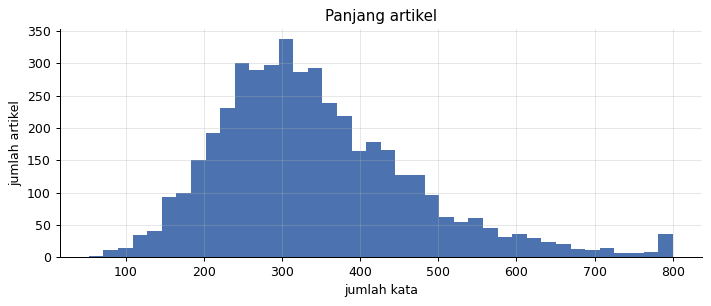

artikel lebih dari 128 kata: 98.6%


In [9]:
lengths = data["article"].str.split().str.len()
fig, ax = plt.subplots()
lengths.clip(upper=800).plot.hist(bins=40, ax=ax, color="#4C72B0")
ax.set(title="Panjang artikel", xlabel="jumlah kata", ylabel="jumlah artikel")
plt.tight_layout()
plt.show()
print(f"artikel lebih dari 128 kata: {(lengths > 128).mean():.1%}")

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Dengan 12 kata pertama, BM25 sudah terlalu mudah (MRR 0,98) | Kueri dibuat lebih sulit dari 5 kata acak |
| 98,6% artikel lebih dari 128 kata | Embedding hanya membaca awal artikel, BM25 tetap membaca seluruh artikel |
| Kategori `inspirasi` kecil | Laporkan skor per kategori dengan jumlahnya |

## 5. Preprocessing

Untuk BM25: huruf kecil dan kata saja. Untuk embedding: awal artikel, karena model membaca maksimal 128 token.
Kueri berasal dari kata acak di kalimat pertama ringkasan.

In [10]:
TOKEN_RE = re.compile(r"[a-z0-9]+")


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(text.lower())


rng = np.random.default_rng(SEED)
query_index = rng.choice(len(data), SETTINGS["n_queries"], replace=False)


def make_query(summary: str) -> str:
    """Ambil beberapa kata isi secara acak, dengan urutan tetap."""
    words = [w for w in summary.lower().split() if len(w) > 2]
    picks = sorted(
        rng.choice(len(words), min(SETTINGS["query_word_limit"], len(words)), replace=False)
    )
    return " ".join(words[i] for i in picks)


queries = [make_query(data["first_summary"].iloc[i]) for i in query_index]
gold = query_index.copy()
corpus_tokens = [tokenize(t) for t in data["article"]]
corpus_text = data["article"].map(lambda t: " ".join(t.split()[:150]).lower()).tolist()
print("contoh kueri:", queries[0])

contoh kueri: pejabat mengoleksi mewah bermerk ratusan


## 6. Validasi

Tiap kueri punya satu dokumen benar. Metriknya MRR@10, Recall@k, dan NDCG@10. Metrik diuji dulu.

In [11]:
def retrieval_scores(rankings: np.ndarray, answers: np.ndarray) -> dict[str, float]:
    """rankings: indeks dokumen terurut per kueri."""
    position = np.array(
        [np.where(row == a)[0][0] if a in row else 10**6 for row, a in zip(rankings, answers)]
    )
    output = {"mrr@10": float(np.mean(np.where(position < 10, 1 / (position + 1), 0)))}
    for k in KS:
        output[f"recall@{k}"] = float(np.mean(position < k))
    output["ndcg@10"] = float(np.mean(np.where(position < 10, 1 / np.log2(position + 2), 0)))
    return {k: round(v, 4) for k, v in output.items()}


_check = retrieval_scores(np.array([[1, 0], [0, 1]]), np.array([1, 1]))
assert _check["mrr@10"] == 0.75 and _check["recall@1"] == 0.5
results: list[dict] = []


def record(name: str, rankings: np.ndarray) -> None:
    results.append({"metode": name, **retrieval_scores(rankings, gold)})
    print(results[-1])

## 7. Baseline

BM25, metode klasik yang sering sulit dikalahkan untuk kueri dengan kata yang persis sama.

In [12]:
from rank_bm25 import BM25Okapi  # noqa: E402

TOP_N = 100
with stage("bm25"):
    bm25 = BM25Okapi(corpus_tokens)
    bm25_scores = np.vstack([bm25.get_scores(tokenize(q)) for q in queries])
bm25_rank = np.argsort(-bm25_scores, axis=1)[:, :TOP_N]
record("bm25", bm25_rank)

[waktu] bm25: 8 detik
{'metode': 'bm25', 'mrr@10': 0.9045, 'recall@1': 0.863, 'recall@5': 0.959, 'recall@10': 0.972, 'ndcg@10': 0.9212}


## 8. Model Utama

**Dense retrieval** dengan e5, yang bisa menemukan dokumen walau katanya berbeda. **Hybrid (RRF)** menggabungkan
peringkat BM25 dan dense tanpa parameter yang perlu difit.

In [13]:
def rrf_merge(rank_a: np.ndarray, rank_b: np.ndarray, n_docs: int) -> np.ndarray:
    """Reciprocal Rank Fusion: skor dijumlahkan dari kedua peringkat."""
    merged = []
    for row_a, row_b in zip(rank_a, rank_b):
        scores: dict[int, float] = {}
        for row in (row_a, row_b):
            for position, doc in enumerate(row):
                scores[int(doc)] = scores.get(int(doc), 0.0) + 1 / (RRF_K + position + 1)
        merged.append(sorted(scores, key=scores.get, reverse=True)[:TOP_N])
    return np.array(merged)


if USE_PRETRAINED:
    with stage("dense"):
        doc_vectors = e5_embed(corpus_text, prefix="passage: ")
        query_vectors = e5_embed(queries, prefix="query: ")
        dense_rank = np.argsort(-(query_vectors @ doc_vectors.T), axis=1)[:, :TOP_N]
    record("dense_e5", dense_rank)
    hybrid_rank = rrf_merge(bm25_rank, dense_rank, len(data))
    record("hybrid_rrf", hybrid_rank)
else:
    hybrid_rank = bm25_rank

[waktu] dense: 48 detik
{'metode': 'dense_e5', 'mrr@10': 0.7331, 'recall@1': 0.665, 'recall@5': 0.821, 'recall@10': 0.865, 'ndcg@10': 0.7651}
{'metode': 'hybrid_rrf', 'mrr@10': 0.8617, 'recall@1': 0.808, 'recall@5': 0.927, 'recall@10': 0.964, 'ndcg@10': 0.8865}


## 9. Post-processing

**Rerank.** Dokumen teratas hasil hybrid dinilai ulang oleh cross-encoder yang membaca kueri dan dokumen
bersamaan. Lebih akurat, tapi terlalu lambat untuk seluruh korpus, jadi hanya dipakai untuk kandidat teratas.

In [14]:
from transformers import AutoModelForSequenceClassification as RerankModel  # noqa: E402
from transformers import AutoTokenizer as RerankTokenizer  # noqa: E402


@torch.inference_mode()
def rerank(rankings: np.ndarray, top: int, batch_size: int = 64) -> np.ndarray:
    tokenizer = RerankTokenizer.from_pretrained(MODEL_DIR / "reranker")
    model = RerankModel.from_pretrained(MODEL_DIR / "reranker").to(DEVICE).eval()
    output = []
    for query, row in zip(queries, rankings):
        candidates = row[:top]
        scores = []
        for start in range(0, len(candidates), batch_size):
            docs = [corpus_text[int(i)] for i in candidates[start : start + batch_size]]
            tokens = tokenizer(
                [query] * len(docs),
                docs,
                padding=True,
                truncation=True,
                max_length=256,
                return_tensors="pt",
            ).to(DEVICE)
            scores.append(model(**tokens).logits.float().squeeze(-1).cpu().numpy())
        order = np.argsort(-np.concatenate(scores))
        output.append(np.concatenate([candidates[order], row[top:]]))
    del model
    torch.cuda.empty_cache()
    return np.array(output)


if USE_PRETRAINED:
    with stage("rerank"):
        final_rank = rerank(hybrid_rank, SETTINGS["rerank_top"])
    record("hybrid_plus_rerank", final_rank)
else:
    final_rank = hybrid_rank

[waktu] rerank: 288 detik
{'metode': 'hybrid_plus_rerank', 'mrr@10': 0.947, 'recall@1': 0.928, 'recall@5': 0.968, 'recall@10': 0.976, 'ndcg@10': 0.9542}


## 10. Post-analysis

**Tabel perbandingan.**

In [15]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,metode,mrr@10,recall@1,recall@5,recall@10,ndcg@10
0,bm25,0.9045,0.863,0.959,0.972,0.9212
1,dense_e5,0.7331,0.665,0.821,0.865,0.7651
2,hybrid_rrf,0.8617,0.808,0.927,0.964,0.8865
3,hybrid_plus_rerank,0.9470,0.928,0.968,0.976,0.9542


**Di mana rerank dibatasi oleh kandidat?** Kalau jawaban benar tidak masuk kandidat, rerank tidak mungkin
memperbaikinya. Nilai ini menjadi batas atas.

In [16]:
ceiling = np.mean(
    [answer in row[: SETTINGS["rerank_top"]] for row, answer in zip(hybrid_rank, gold)]
)
print(f"jawaban ada di {SETTINGS['rerank_top']} kandidat teratas: {ceiling:.1%}")

jawaban ada di 50 kandidat teratas: 98.9%


**Skor per kategori** dan contoh kueri yang gagal.

In [17]:
position = np.array(
    [np.where(row == a)[0][0] if a in row else TOP_N for row, a in zip(final_rank, gold)]
)
by_category = pd.DataFrame(
    {"kategori": data["category"].to_numpy()[gold], "kena@10": position < 10}
)
print(by_category.groupby("kategori")["kena@10"].agg(["size", "mean"]).round(3))
failures = np.argsort(-position)[:5]
pd.DataFrame(
    {
        "kueri": [queries[i] for i in failures],
        "teratas": [corpus_text[int(final_rank[i, 0])][:70] for i in failures],
        "seharusnya": [corpus_text[int(gold[i])][:70] for i in failures],
    }
)

             size   mean
kategori                
hiburan        86  0.953
inspirasi       8  1.000
olahraga      259  0.981
showbiz       125  0.984
tajuk utama   389  0.987
teknologi     133  0.940


,kueri,teratas,seharusnya
0,pada lanjutan mandala minggu 2017,persipura jayapura berhasil menuai kemenangan pada pekan ke - 32 liga,"bandung , juara.net - pelatih persija , stefano cugurra , menyayangkan"
1,menurut laporan yang menjadi kasus,aliansi jurnalis independen ( aji ) kota jayapura mengkritik implement,"ho chi minh city ( antara news ) - kota ho chi minh , vietnam , kembal"
2,gagal pada liga primer stadion,"jakarta , cnn indonesia - - arsenal gagal meraih tiga poin di kandang",stoke city dan manchester united mengawali pertandingan dengan hati-ha
3,tujuh tanpa saat tampil rabu,"jakarta , cnn indonesia - - pelatih persipura jayapura wanderley jr me","bandung , juara.net - salah satu legenda persib , dede iskandar , meny"
4,gemborkan nyatanya ini seharmonis itu,"jakarta , cnn indonesia - - aktor hollywood , miles teller kembali men","jakarta , cnn indonesia - - hampir empat bulan berlalu , pelaku penyir"


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
pd.DataFrame(
    {
        "id_kueri": range(len(queries)),
        "dokumen_top10": [" ".join(map(str, r[:10])) for r in final_rank],
    }
).to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "retrieval",
    len(data),
    {r["metode"]: {"mrr@10": r["mrr@10"], "recall@10": r["recall@10"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=retrieval mode=penuh n_rows=4449 total_detik=361 gpu=True
{
 "bm25": {
  "mrr@10": 0.9045,
  "recall@10": 0.972
 },
 "dense_e5": {
  "mrr@10": 0.7331,
  "recall@10": 0.865
 },
 "hybrid_rrf": {
  "mrr@10": 0.8617,
  "recall@10": 0.964
 },
 "hybrid_plus_rerank": {
  "mrr@10": 0.947,
  "recall@10": 0.976
 }
}


**Poin untuk presentasi**

- Hybrid + rerank terbaik: MRR@10 0,947, sedangkan BM25 0,9045 dan dense 0,7331.
- Hybrid saja justru lebih rendah dari BM25 (0,8617). Yang menaikkan skor adalah reranker.
- Rerank memakan 288 detik, sedangkan BM25 hanya 8 detik. Mode penuh membaca 50 kandidat, dan jawaban benar ada di kandidat 98,9%.
- Metode tanpa model (BM25) sudah kuat, jadi aman kalau pretrained dilarang.